# Customer Segmentation Analysis Using K-Means Clustering

**Objective:** Apply K-Means clustering to segment customers based on purchasing behaviour and identify targeted marketing strategies.

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

plt.style.use("ggplot")

## Load Dataset

In [2]:
df = pd.read_csv("online_retail.csv", encoding="ISO-8859-1")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Dataset Inspection

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (541909, 8)


## Column Names

In [4]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


## Dataset Information and Data Types

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 69.3 MB


## Missing Values

In [6]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


## Data Cleaning

In [7]:
df_clean = df.copy()
df_clean = df_clean.dropna(subset=["CustomerID"])
df_clean = df_clean[
    ~df_clean["InvoiceNo"].str.startswith("C", na=False)
]

df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["TotalPrice"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)
print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

Original Dataset Shape: (541909, 8)
Cleaned Dataset Shape: (397884, 9)

Missing Values After Cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64


## Descriptive Statistics

##### Calculate average purchase value, purchase frequency, and customer lifetime value to understand customer purchasing behaviour.

In [8]:
customer_spending = df_clean.groupby("CustomerID")["TotalPrice"].sum()

purchase_frequency = df_clean.groupby("CustomerID")["InvoiceNo"].nunique()

average_purchase_value = customer_spending / purchase_frequency

print("Average Purchase Value:", round(average_purchase_value.mean(), 2))
print("Average Purchase Frequency:", round(purchase_frequency.mean(), 2))
print("Average Customer Lifetime Value:", round(customer_spending.mean(), 2))

Average Purchase Value: 419.17
Average Purchase Frequency: 4.27
Average Customer Lifetime Value: 2054.27


## RFM Analysis

##### RFM analysis evaluates customers based on Recency, Frequency, and Monetary value to identify different purchasing behaviours.

In [9]:
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)


In [10]:
rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
})


In [11]:
rfm.columns = ["Recency", "Frequency", "Monetary"]
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


### RFM Summary Statistics

In [12]:
rfm.describe().round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


In [13]:
print("Average Recency:", rfm['Recency'].mean())
print("Average Frequency:", rfm['Frequency'].mean())
print("Average Monetary Value:", rfm['Monetary'].mean())

Average Recency: 92.53642231443061
Average Frequency: 4.272014753342554
Average Monetary Value: 2054.2664601198708


### RFM Analysis Visualization

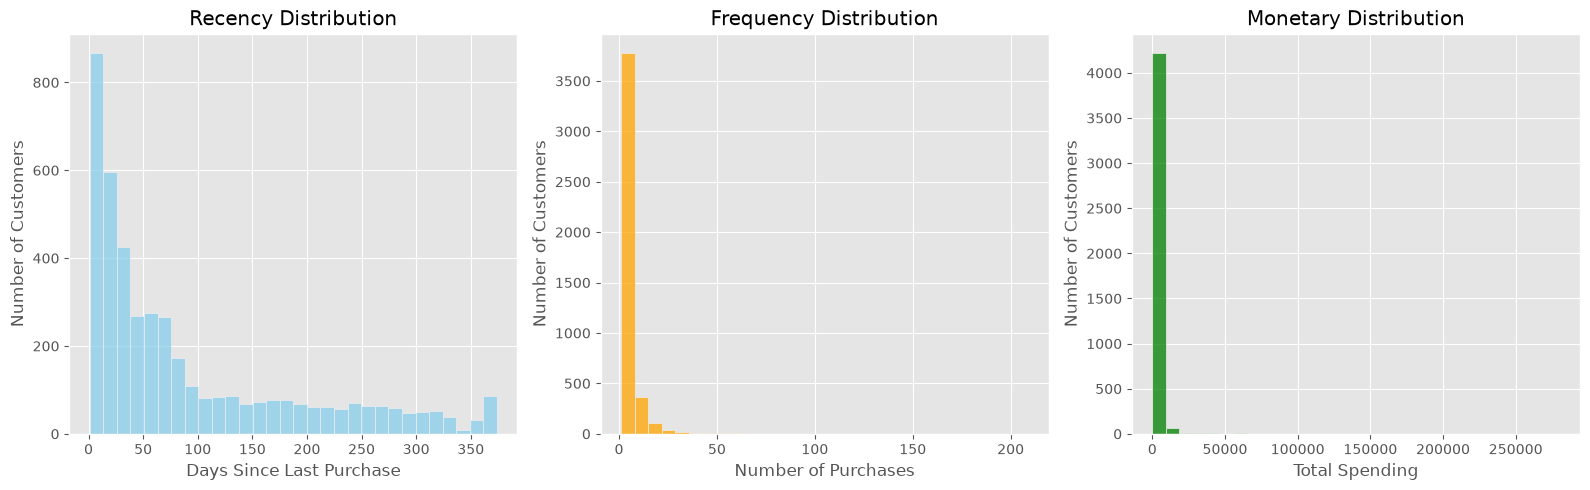

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(rfm["Recency"], bins=30, color="skyblue", ax=axes[0])
axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Days Since Last Purchase")
axes[0].set_ylabel("Number of Customers")

sns.histplot(rfm["Frequency"], bins=30, color="orange", ax=axes[1])
axes[1].set_title("Frequency Distribution")
axes[1].set_xlabel("Number of Purchases")
axes[1].set_ylabel("Number of Customers")

sns.histplot(rfm["Monetary"], bins=30, color="green", ax=axes[2])
axes[2].set_title("Monetary Distribution")
axes[2].set_xlabel("Total Spending")
axes[2].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## Data Standardisation

In [15]:
features = rfm[['Recency', 'Frequency', 'Monetary']]

In [16]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(features)

In [17]:
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

In [18]:
rfm_scaled_df.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.358668
12347,-0.905340,0.354417,0.250966
12348,-0.175360,-0.035340,-0.028596
12349,-0.735345,-0.425097,-0.033012
12350,2.174578,-0.425097,-0.191347


In [19]:
rfm_scaled_df.agg(['mean', 'std']).round(2)

,Recency,Frequency,Monetary
mean,0.0,0.0,0.0
std,1.0,1.0,1.0


## Elbow Method for Optimal K

In [20]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

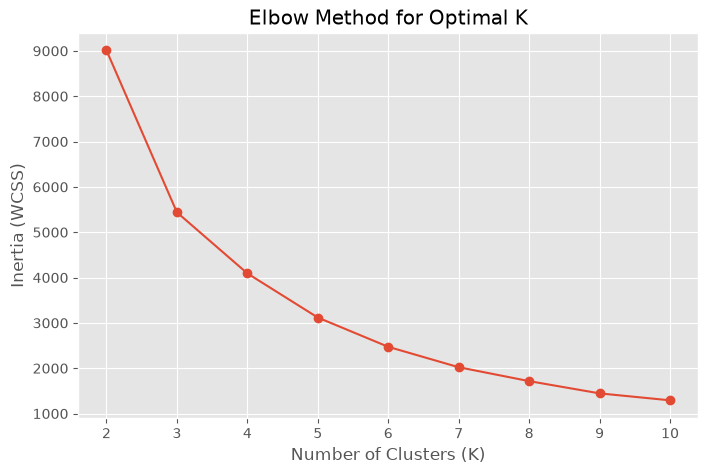

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(K_range, inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method for Optimal K')
plt.xticks(list(K_range))
plt.grid(True)

plt.show()

## Applying K-Means Clustering

In [22]:
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,0
12347,2,7,4310.00,1
12348,75,4,1797.24,1
12349,19,1,1757.55,1
12350,310,1,334.40,0


## Evaluate Clustering Quality

In [23]:
from sklearn.metrics import silhouette_score

silhouette_avg = silhouette_score(
    rfm_scaled,
    rfm['Cluster']
)

print("Silhouette Score:", round(silhouette_avg, 3))

Silhouette Score: 0.594


## Customer Cluster Visualization

### Recency vs Frequency

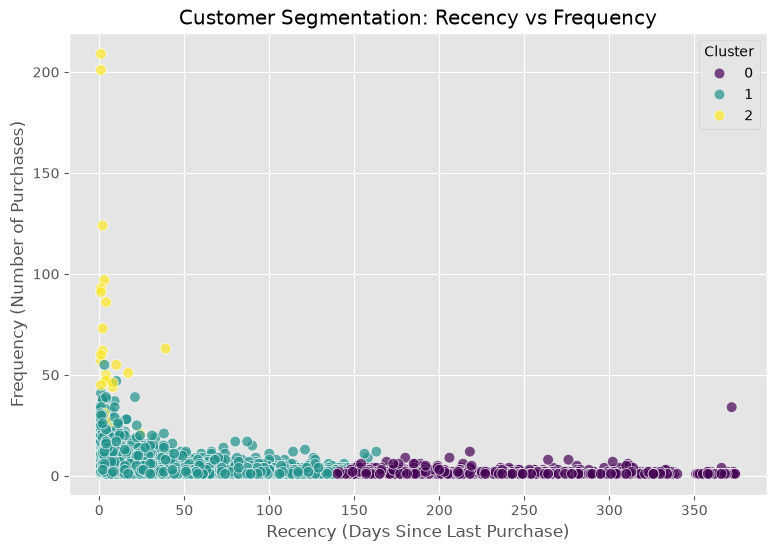

In [24]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis',
    s=60,
    alpha=0.7
)

plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency (Days Since Last Purchase)')
plt.ylabel('Frequency (Number of Purchases)')
plt.legend(title='Cluster')
plt.grid(True)

plt.show()

### Frequency vs Monetary

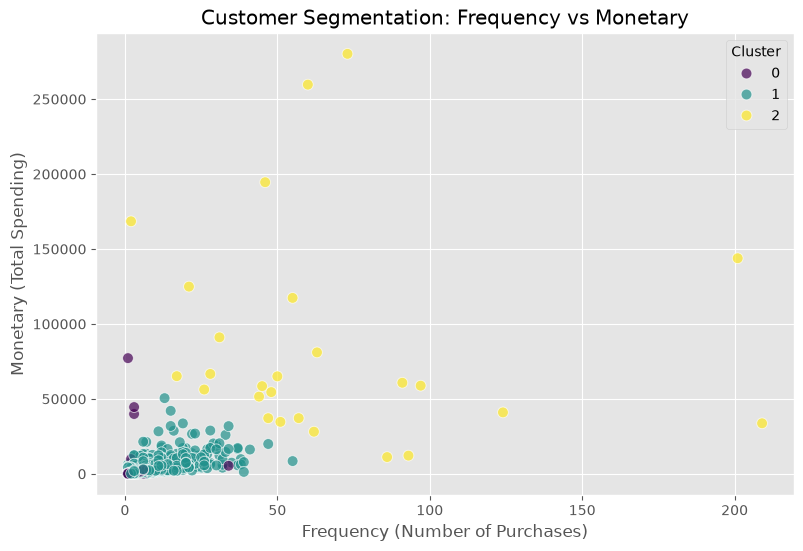

In [25]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=60,
    alpha=0.7
)

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Frequency (Number of Purchases)')
plt.ylabel('Monetary (Total Spending)')
plt.legend(title='Cluster')
plt.grid(True)

plt.show()

## Cluster Profiling

In [26]:
cluster_profile = rfm.groupby('Cluster').agg(
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Customer_Count=('Recency', 'count')
).round(2)

print("Customer Cluster Profiles:")
display(cluster_profile)

Customer Cluster Profiles:


,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Count
Cluster,,,,
0,247.11,1.58,631.42,1082
1,41.45,4.67,1855.94,3230
2,6.04,66.42,85904.35,26


## Customer Segment Analysis

- **Cluster 0 – Inactive / Low-Engagement Customers**
- **Cluster 1 – Active / Regular Customers**
- **Cluster 2 – VIP / High-Value Customers**

## Bar Chart

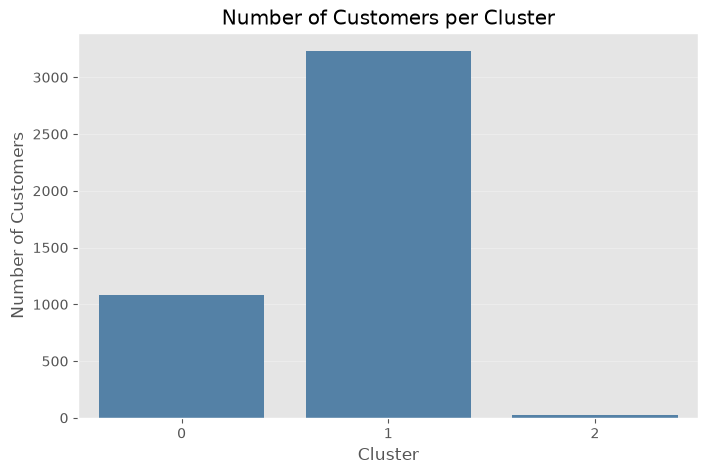

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    color='steelblue'
)

plt.title('Number of Customers per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.3)

plt.show()

## Key Insights and Marketing Recommendations

- **VIP Customers:** 26 customers have exceptionally high spending and purchase frequency. Offer exclusive VIP benefits, priority support, and personalized services to retain them.

- **Loyal Customers:** 3,230 customers form the largest segment (74.5%), with an average of 4.67 purchases. Introduce loyalty rewards and personalized recommendations to encourage repeat purchases.

- **Inactive Customers:** 1,082 customers have low purchase frequency and an average recency of 247 days. Use personalized win-back offers and discounts to reactivate them.

- **Overall Marketing Strategy:** Focus on retaining VIP customers, strengthening customer loyalty, and re-engaging inactive customers through targeted marketing campaigns.